# Part A - Data Engineer: Flowers102
Team members: Yerkebulan Abdissattar, Daniyal Adilbekuly, Dias Tursunbai.

Use the first 10 classes (labels 0-9). Run from top to bottom. Required packages: torch, torchvision, scipy, numpy, matplotlib. The first run downloads Flowers102 automatically and needs internet access.

In [1]:
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
NUM_CLASSES = 10
IMAGE_SIZE = 224
BATCH_SIZE = 32
DATA_ROOT = Path.cwd() / "data"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

CLASS_NAMES = [
    "pink primrose", "hard-leaved pocket orchid", "canterbury bells",
    "sweet pea", "english marigold", "tiger lily", "moon orchid",
    "bird of paradise", "monkshood", "globe thistle"
]

## Load and check the dataset first
Keep the official train, validation and test partitions. Filter each partition to labels 0-9 without mixing images between partitions. Torchvision already uses zero-based labels.

In [2]:
raw_datasets = {
    split: datasets.Flowers102(root=str(DATA_ROOT), split=split, download=True)
    for split in ("train", "val", "test")
}

split_indices = {}
for split, dataset in raw_datasets.items():
    selected = []
    for index in range(len(dataset)):
        image, label = dataset[index]
        if label < NUM_CLASSES:
            image.convert("RGB").load()
            selected.append(index)
    if not selected:
        raise ValueError(f"No images found for {split}")
    split_indices[split] = selected
    image, label = dataset[selected[0]]
    print(f"{split}: {len(selected)} images; first image {image.size}; label {label}")

print("All selected images loaded successfully")

100%|██████████| 345M/345M [01:14<00:00, 4.62MB/s] 


Extracting C:\Users\adilb\PycharmProjects\Sample\data\flowers-102\102flowers.tgz to C:\Users\adilb\PycharmProjects\Sample\data\flowers-102


100%|██████████| 502/502 [00:00<?, ?B/s] 


100%|██████████| 15.0k/15.0k [00:00<00:00, 15.0MB/s]


train: 100 images; first image (754, 500); label 0
val: 100 images; first image (606, 500); label 0
test: 322 images; first image (523, 500); label 0
All selected images loaded successfully


## Preprocessing and augmentation
Resize to 224 x 224 and normalize using ImageNet mean and standard deviation. Training uses horizontal flips, rotations and color jitter. Validation and test use deterministic preprocessing only.

In [3]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

train_dataset = Subset(
    datasets.Flowers102(str(DATA_ROOT), split="train", transform=train_transform),
    split_indices["train"]
)
val_dataset = Subset(
    datasets.Flowers102(str(DATA_ROOT), split="val", transform=val_test_transform),
    split_indices["val"]
)
test_dataset = Subset(
    datasets.Flowers102(str(DATA_ROOT), split="test", transform=val_test_transform),
    split_indices["test"]
)

train_ds = train_dataset
val_ds = val_dataset
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, generator=loader_generator)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

## Class distribution

Class                                Train    Val   Test
0: pink primrose                        10     10     20
1: hard-leaved pocket orchid            10     10     40
2: canterbury bells                     10     10     20
3: sweet pea                            10     10     36
4: english marigold                     10     10     45
5: tiger lily                           10     10     25
6: moon orchid                          10     10     20
7: bird of paradise                     10     10     65
8: monkshood                            10     10     26
9: globe thistle                        10     10     25


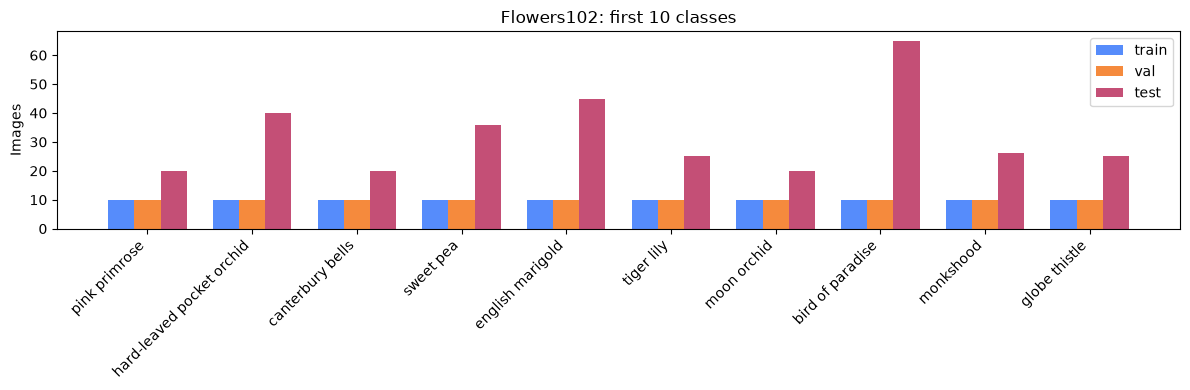

In [4]:
class_counts = {}
for split, dataset in raw_datasets.items():
    labels = [dataset[index][1] for index in split_indices[split]]
    class_counts[split] = np.bincount(labels, minlength=NUM_CLASSES)
    assert np.all(class_counts[split] > 0)

print(f"{'Class':<35} {'Train':>6} {'Val':>6} {'Test':>6}")
for label, name in enumerate(CLASS_NAMES):
    print(f"{label}: {name:<32} {class_counts['train'][label]:>6} {class_counts['val'][label]:>6} {class_counts['test'][label]:>6}")

fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(NUM_CLASSES)
for offset, split in zip((-0.25, 0, 0.25), ("train", "val", "test")):
    ax.bar(x + offset, class_counts[split], width=0.25, label=split)
ax.set_xticks(x, CLASS_NAMES, rotation=45, ha="right")
ax.set_ylabel("Images")
ax.set_title("Flowers102: first 10 classes")
ax.legend()
plt.tight_layout()
plt.show()

## Eight labeled training samples

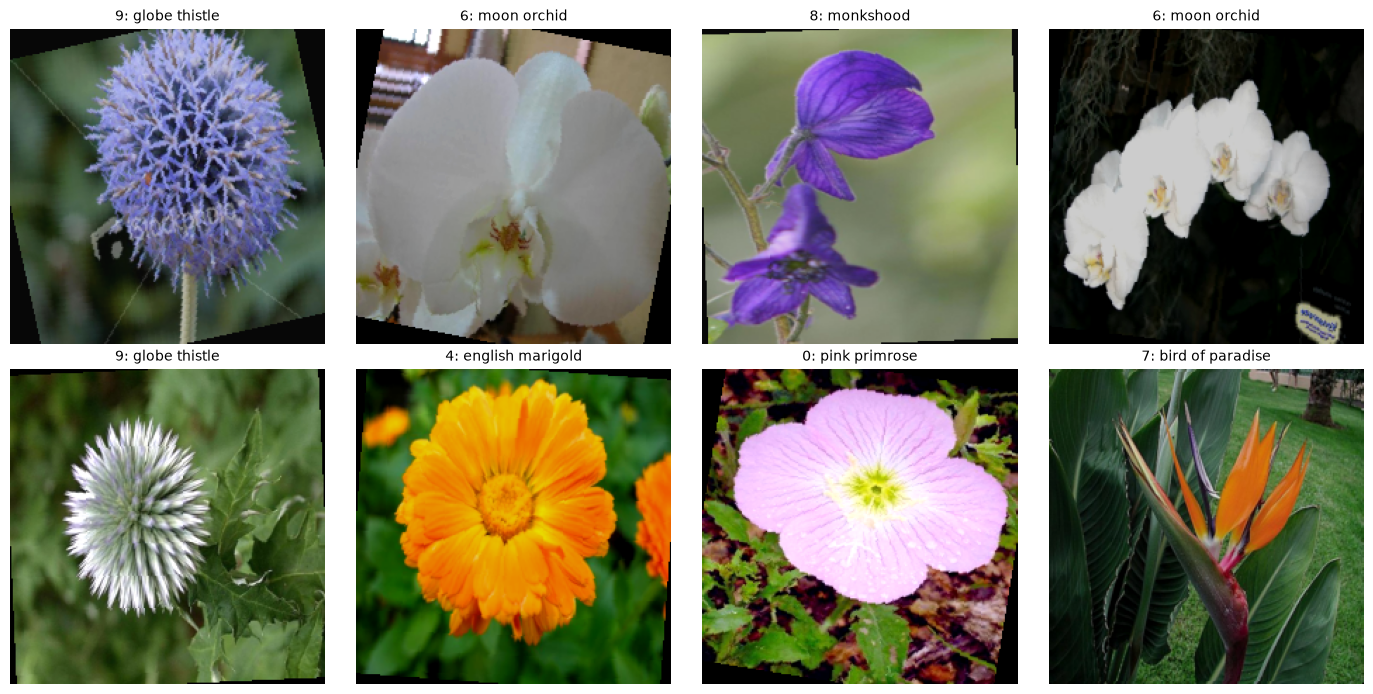

In [5]:
def denormalize(tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (tensor.detach().cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

with torch.random.fork_rng():
    torch.manual_seed(SEED)
    preview_indices = np.random.default_rng(SEED).choice(len(train_dataset), size=8, replace=False)
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax, index in zip(axes.flat, preview_indices):
        image, label = train_dataset[int(index)]
        ax.imshow(denormalize(image))
        ax.set_title(f"{label}: {CLASS_NAMES[label]}", fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## Pipeline validation

In [6]:
for split, dataset in (("train", train_dataset), ("val", val_dataset), ("test", test_dataset)):
    check_loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    images, labels = next(iter(check_loader))
    assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
    assert images.dtype == torch.float32
    assert torch.isfinite(images).all()
    assert labels.dtype == torch.int64
    assert ((labels >= 0) & (labels < NUM_CLASSES)).all()
    print(f"{split}: batch {tuple(images.shape)}, labels {tuple(labels.shape)}")

assert torch.equal(val_dataset[0][0], val_dataset[0][0])
assert torch.equal(test_dataset[0][0], test_dataset[0][0])
print("Data pipeline checks passed")

train: batch (32, 3, 224, 224), labels (32,)
val: batch (32, 3, 224, 224), labels (32,)
test: batch (32, 3, 224, 224), labels (32,)
Data pipeline checks passed


Ready for the Model Engineer: `train_loader`, `val_loader`, `test_loader`, `NUM_CLASSES`, `CLASS_NAMES`, `train_transform`, `val_test_transform`. Model implementation, training and evaluation are outside Part A.